In [ ]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from palmer_penguins.data import PROJECT_ROOT, load_clean

FIG = PROJECT_ROOT / "reports" / "figures"
df = load_clean()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### Вопрос 1. Длина и глубина клюва
Посчитаем выборочный коэффициент корреляции для длины и глубины клювов.

In [6]:
df["bill_length_mm"].corr(df["bill_depth_mm"])

np.float64(-0.2350528703555326)

In [7]:
df.groupby("species", observed=True)[["bill_length_mm", "bill_depth_mm"]].corr()

bill_length_mm  bill_depth_mm
species                                                
Adelie    bill_length_mm        1.000000       0.391492
          bill_depth_mm         0.391492       1.000000
Chinstrap bill_length_mm        1.000000       0.653536
          bill_depth_mm         0.653536       1.000000
Gentoo    bill_length_mm        1.000000       0.643384
          bill_depth_mm         0.643384       1.000000

По всем птицам сразу получится $r \approx -0.24$, то есть чем длиннее клюв, тем он мельче. А внутри каждого вида связь положительная: $r \approx 0.39,\ 0.65,\ 0.64$. При объединении групп зависимость меняет знак. Это парадокс Симпсона.

Причина в том, что на оба признака влияет третья переменная - вид. У Gentoo клювы длинные и неглубокие, у Adelie короткие и глубокие. Облака точек разных видов сдвинуты друг относительно друга так, что общая прямая наклоняется вниз, хотя внутри каждого облака наклон положительный.

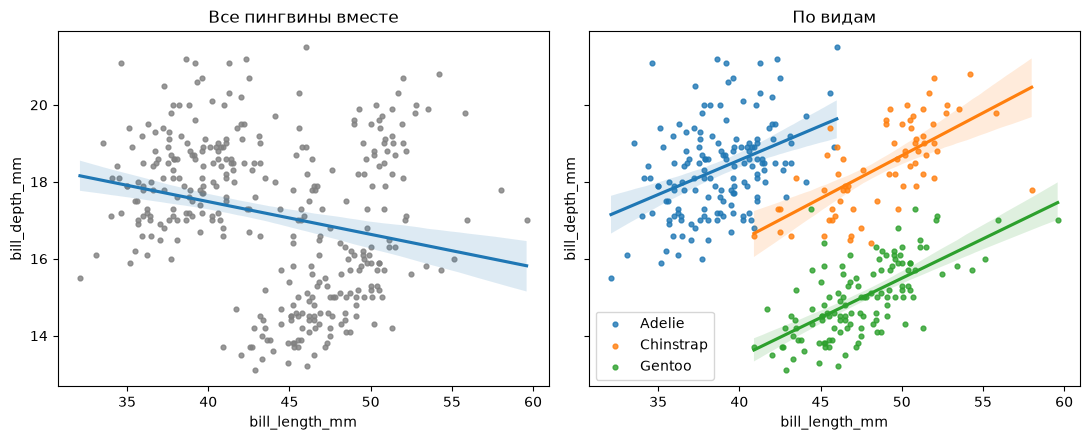

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
sns.regplot(
    data=df,
    x="bill_length_mm",
    y="bill_depth_mm",
    ax=axes[0],
    scatter_kws={"s": 12, "color": "gray"},
)
axes[0].set_title("Все пингвины вместе")
for species, part in df.groupby("species", observed=True):
    sns.regplot(
        data=part,
        x="bill_length_mm",
        y="bill_depth_mm",
        ax=axes[1],
        label=species,
        scatter_kws={"s": 12},
    )
axes[1].set_title("По видам")
axes[1].legend()
fig.tight_layout()
fig.savefig(FIG / "simpson.png", dpi=120)

### Вопрос 2. Различается ли масса самцов и самок Adelie?

Массы самцов $X_1,\dots,X_{n_1}$ — независимые одинаково распределённые случайные величины со средним $\mu_1$. Массы самок $Y_1,\dots,Y_{n_2}$ устроены так же, со средним $\mu_2$. Проверяем гипотезу $H_0:\ \mu_1=\mu_2$ против $H_1:\ \mu_1\ne\mu_2$.

Используем t-критерий Уэлча. В отличие от классического критерия Стьюдента, он не требует, чтобы дисперсии групп были равны. Статистика критерия:

$$t = \frac{\bar X - \bar Y}{\sqrt{\dfrac{s_1^2}{n_1} + \dfrac{s_2^2}{n_2}}},$$

где $s_1^2, s_2^2$ — несмещённые выборочные дисперсии. Знаменатель — это оценка стандартного отклонения разности $\bar X-\bar Y$. При $H_0$ статистика $t$ приближённо имеет распределение Стьюдента с числом степеней свободы, которое вычисляется по формуле Уэлча–Саттертуэйта.

In [ ]:
adelie = df[df["species"] == "Adelie"].dropna(subset=["sex"])
males = adelie.loc[adelie["sex"] == "male", "body_mass_g"]
females = adelie.loc[adelie["sex"] == "female", "body_mass_g"]

print(f"самцы: n={len(males)}, среднее {males.mean():.0f} г")
print(f"самки: n={len(females)}, среднее {females.mean():.0f} г")

res = stats.ttest_ind(
    males, females, equal_var=False
)  # equal_var=False — это и есть Уэлч
print(res)
ci = res.confidence_interval(confidence_level=0.95)
print(f"95% ДИ: [{ci.low:.0f}, {ci.high:.0f}] г")

самцы: n=73, среднее 4043 г
самки: n=73, среднее 3369 г
TtestResult(statistic=np.float64(13.126285923485874), pvalue=np.float64(6.402319748031804e-26), df=np.float64(135.69357893530383))
95% ДИ: [573, 776] г


Самцы тяжелее примерно на 600–800 г, то есть на 17–23%

### Вопрос 3. Можно ли определить вид по клюву?

Будем строить логистическую регрессию. В качестве baseline возьмем константный ответ "Adelie", так как это самый частый вид.

In [14]:
X = df[["bill_length_mm", "bill_depth_mm"]]
y = df["species"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

baseline = cross_val_score(DummyClassifier(strategy="most_frequent"), X, y, cv=cv)
model = make_pipeline(StandardScaler(), LogisticRegression())
scores = cross_val_score(model, X, y, cv=cv)

print(f"baseline: {baseline.mean():.3f}")
print(f"модель:   {scores.mean():.3f} ± {scores.std():.3f}")

baseline: 0.442
модель:   0.962 ± 0.022


Где именно модель ошибается, покажет матрица ошибок.

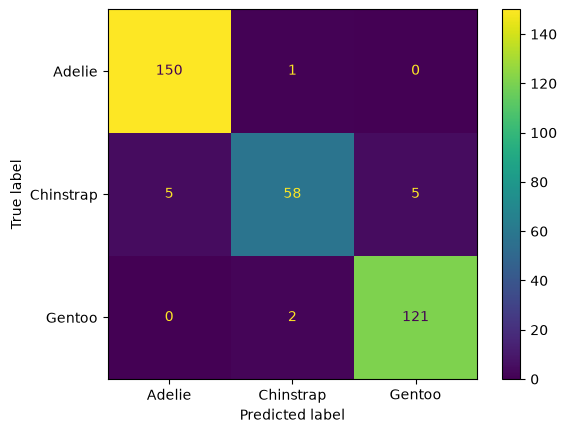

In [18]:
pred = cross_val_predict(model, X, y, cv=cv)
disp = ConfusionMatrixDisplay.from_predictions(y, pred)
disp.figure_.savefig(FIG / "confusion.png", dpi=120)

Больше всего ошибок на Chinstrap: 10 из 68. Это понятно, потому что по длине клюва Chinstrap похожи на Gentoo, а по глубине на Adelie, то есть они находятся между ними.